# OpenSurfaces material recognition workflow

This notebook keeps the preparation work together: existing DMS results, raw OpenSurfaces downloads, annotation matching, cleaning, and the prepared image/mask data used for the next training run. The tables and plots are generated from the files in this project and the research dataset stored on the E: drive.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'datasets').exists():
    ROOT = ROOT.parent
PROJECT = ROOT / 'datasets' / 'opensurfaces'
EXTERNAL = Path(r'E:/Fitwell-OpenSurfaces')
plt.style.use('seaborn-v0_8-whitegrid')
print('Project:', ROOT)
print('OpenSurfaces files:', EXTERNAL)


Project: c:\Users\Samiha Abeda Nur\Downloads\Fitwell-AI
OpenSurfaces files: E:\Fitwell-OpenSurfaces


## 1. Existing DMS model results

,epoch,train_loss,validation_loss,validation_mean_iou
0,1,3.504282,2.223350,0.042478
1,2,2.723889,1.921048,0.088787
2,3,2.339024,2.101596,0.086354
3,4,2.085737,1.905568,0.122801
4,5,1.899756,1.875377,0.139261
5,6,1.767057,1.929401,0.143784
6,7,1.691562,2.292162,0.110125
7,8,1.627830,2.138737,0.133918
8,9,1.572035,2.112112,0.159359
9,10,1.502591,2.318064,0.127765


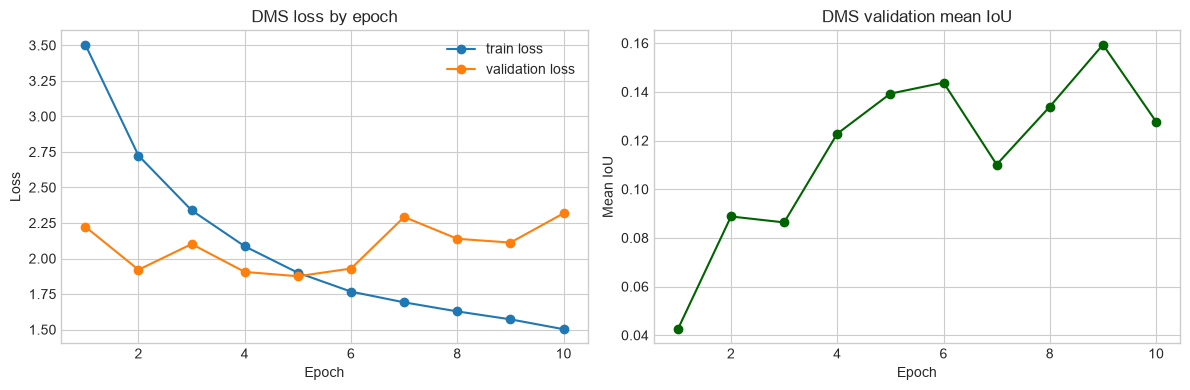

,loss,mean_iou,test_pairs
0,1.481918,0.159261,10


In [2]:
history_path = ROOT / 'training' / 'runs' / 'dms-all-research' / 'history.csv'
metrics_path = ROOT / 'training' / 'runs' / 'dms-all-research' / 'test_metrics.json'
if history_path.exists():
    dms_history = pd.read_csv(history_path)
    display(dms_history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(dms_history['epoch'], dms_history['train_loss'], marker='o', label='train loss')
    validation_loss_column = 'validation_loss' if 'validation_loss' in dms_history.columns else 'val_loss'
    axes[0].plot(dms_history['epoch'], dms_history[validation_loss_column], marker='o', label='validation loss')
    axes[0].set(title='DMS loss by epoch', xlabel='Epoch', ylabel='Loss')
    axes[0].legend()
    iou_column = 'validation_mean_iou' if 'validation_mean_iou' in dms_history.columns else 'val_mean_iou'
    axes[1].plot(dms_history['epoch'], dms_history[iou_column], marker='o', color='darkgreen')
    axes[1].set(title='DMS validation mean IoU', xlabel='Epoch', ylabel='Mean IoU')
    plt.tight_layout()
    plt.show()
else:
    print('DMS history is not available yet:', history_path)
if metrics_path.exists():
    dms_metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([dms_metrics]))


## 2. Raw OpenSurfaces photos

Raw download rows: 1,000


,photo_id,image_path,source_url,status,error
0,57,E:\Fitwell-OpenSurfaces\images\57.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
1,207,E:\Fitwell-OpenSurfaces\images\207.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
2,322,E:\Fitwell-OpenSurfaces\images\322.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
3,396,E:\Fitwell-OpenSurfaces\images\396.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
4,441,E:\Fitwell-OpenSurfaces\images\441.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
5,750,E:\Fitwell-OpenSurfaces\images\750.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
6,777,E:\Fitwell-OpenSurfaces\images\777.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
7,930,E:\Fitwell-OpenSurfaces\images\930.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
8,1046,E:\Fitwell-OpenSurfaces\images\1046.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN
9,1079,E:\Fitwell-OpenSurfaces\images\1079.jpg,http://labelmaterial.s3.amazonaws.com/photos/2...,downloaded,NaN


,status,photos
0,downloaded,1000


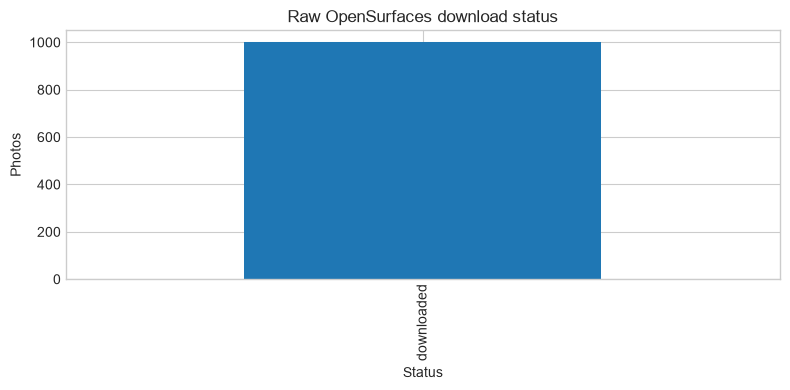

In [3]:
raw_manifest_path = EXTERNAL / 'photo_download_manifest.csv'
if raw_manifest_path.exists():
    raw_photos = pd.read_csv(raw_manifest_path)
    print(f'Raw download rows: {len(raw_photos):,}')
    display(raw_photos.head(10))
    status_counts = raw_photos['status'].value_counts(dropna=False)
    display(status_counts.rename_axis('status').reset_index(name='photos'))
    status_counts.plot(kind='bar', figsize=(8, 4), title='Raw OpenSurfaces download status')
    plt.xlabel('Status'); plt.ylabel('Photos'); plt.tight_layout(); plt.show()
else:
    print('Download manifest not found:', raw_manifest_path)


## 3. Match photos with material annotations

Matched annotation rows: 209


,photo_id,image_path,annotation_count,material_labels,shape_ids
0,207,E:\Fitwell-OpenSurfaces\images\207.jpg,6,Fabric/cloth,37939|37942|37943|37941|37940|37944
1,1189,E:\Fitwell-OpenSurfaces\images\1189.jpg,6,Carpet/rug|Fabric/cloth|Foliage|Leather,177176|177181|177180|177178|177177|177179
2,1476,E:\Fitwell-OpenSurfaces\images\1476.jpg,7,Fabric/cloth|Glass|Paper/tissue|Wood,118154|118155|118156|118152|118150|118151|118153
3,1981,E:\Fitwell-OpenSurfaces\images\1981.jpg,3,Fabric/cloth|Wood,152226|152223|152221
4,2545,E:\Fitwell-OpenSurfaces\images\2545.jpg,7,Glass|Tile|Wood,135653|135660|135652|135656|135663|135658|135649
5,3400,E:\Fitwell-OpenSurfaces\images\3400.jpg,7,Glass|Granite/marble|Painted|Wood,117406|117407|117405|117404|117397|117408|117402
6,4144,E:\Fitwell-OpenSurfaces\images\4144.jpg,4,Leather|Metal|Painted|Tile,177341|177338|177340|177339
7,4446,E:\Fitwell-OpenSurfaces\images\4446.jpg,4,Wood,34279|34283|34282|34280
8,4616,E:\Fitwell-OpenSurfaces\images\4616.jpg,6,Ceramic|Granite/marble|Painted|Wood,161592|161595|161591|161593|161596|161594
9,4899,E:\Fitwell-OpenSurfaces\images\4899.jpg,6,Ceramic|Food|Painted|Tile,177632|177631|177630|177629|177628|177633


Photos with annotations: 209
Material labels: 20


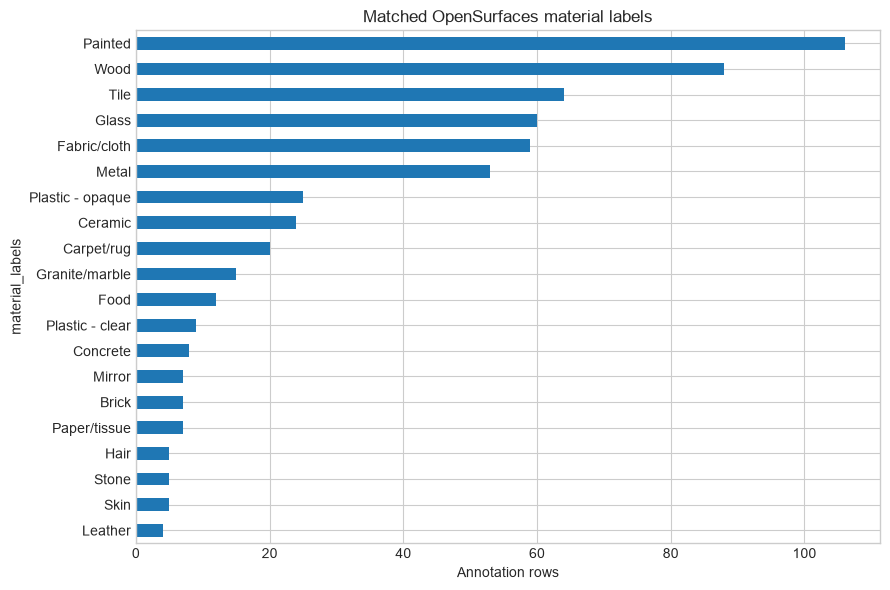

In [4]:
matched_path = PROJECT / 'local_data' / 'opensurfaces_matched_annotations.csv'
if matched_path.exists():
    matched = pd.read_csv(matched_path)
    print(f'Matched annotation rows: {len(matched):,}')
    display(matched.head(10))
    print('Photos with annotations:', matched['photo_id'].nunique())
    label_counts = matched['material_labels'].fillna('').str.split('|').explode().replace('', pd.NA).dropna().value_counts().head(20).sort_values()
    print('Material labels:', len(label_counts))
    label_counts.plot(kind='barh', figsize=(9, 6), title='Matched OpenSurfaces material labels')
    plt.xlabel('Annotation rows'); plt.tight_layout(); plt.show()
else:
    print('Matched annotation table not found:', matched_path)


## 4. Cleaned image and mask tables

Prepared image/mask pairs: 247


,image_id,image_path,label_path,labels,split,status
0,70866,E:\Fitwell-OpenSurfaces\images\70866.jpg,E:\Fitwell-OpenSurfaces\prepared\70866.png,20|52,train,accepted
1,114752,E:\Fitwell-OpenSurfaces\images\114752.jpg,E:\Fitwell-OpenSurfaces\prepared\114752.png,26|29|46,train,accepted
2,115819,E:\Fitwell-OpenSurfaces\images\115819.jpg,E:\Fitwell-OpenSurfaces\prepared\115819.png,43|46|52,train,accepted
3,90515,E:\Fitwell-OpenSurfaces\images\90515.jpg,E:\Fitwell-OpenSurfaces\prepared\90515.png,29,train,accepted
4,6689,E:\Fitwell-OpenSurfaces\images\6689.jpg,E:\Fitwell-OpenSurfaces\prepared\6689.png,46,train,accepted
5,7575,E:\Fitwell-OpenSurfaces\images\7575.jpg,E:\Fitwell-OpenSurfaces\prepared\7575.png,7|29,train,accepted
6,10357,E:\Fitwell-OpenSurfaces\images\10357.jpg,E:\Fitwell-OpenSurfaces\prepared\10357.png,29|46,train,accepted
7,82895,E:\Fitwell-OpenSurfaces\images\82895.jpg,E:\Fitwell-OpenSurfaces\prepared\82895.png,7|26,train,accepted
8,8208,E:\Fitwell-OpenSurfaces\images\8208.jpg,E:\Fitwell-OpenSurfaces\prepared\8208.png,29,train,accepted
9,64760,E:\Fitwell-OpenSurfaces\images\64760.jpg,E:\Fitwell-OpenSurfaces\prepared\64760.png,7|52,train,accepted


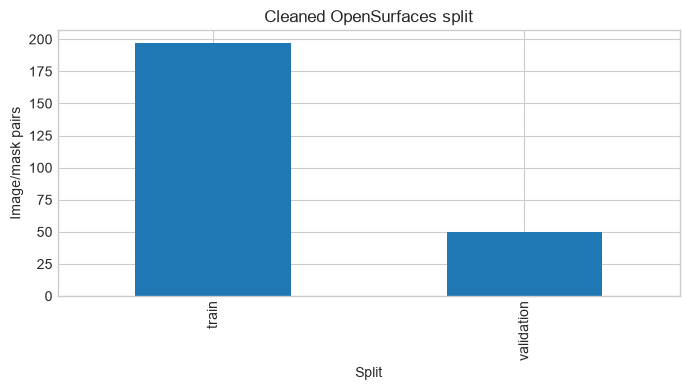

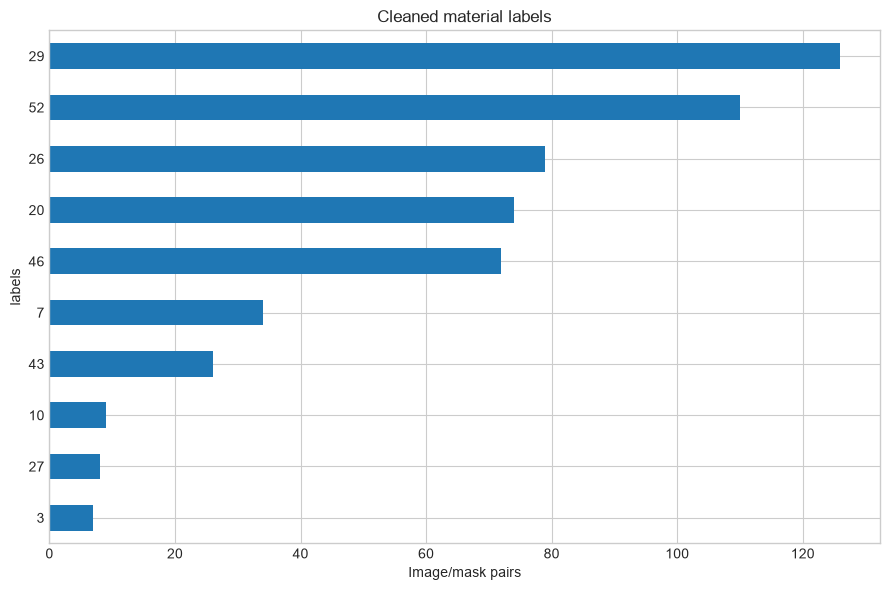

,split,labels,pairs
0,train,10,2
1,train,10|26|52,1
2,train,10|29,1
3,train,10|43|46,2
4,train,20,5
...,...,...,...
88,validation,7|20|26|52,1
89,validation,7|20|27|29|46,1
90,validation,7|26,1
91,validation,7|29,1


In [5]:
prepared_manifest_path = EXTERNAL / 'prepared' / 'manifest.csv'
if prepared_manifest_path.exists():
    prepared = pd.read_csv(prepared_manifest_path)
    print(f'Prepared image/mask pairs: {len(prepared):,}')
    display(prepared.head(10))
    split_counts = prepared['split'].value_counts()
    split_counts.plot(kind='bar', figsize=(7, 4), title='Cleaned OpenSurfaces split')
    plt.xlabel('Split'); plt.ylabel('Image/mask pairs'); plt.tight_layout(); plt.show()
    clean_labels = prepared['labels'].fillna('').str.split('|').explode().replace('', pd.NA).dropna().value_counts().sort_values()
    clean_labels.plot(kind='barh', figsize=(9, 6), title='Cleaned material labels')
    plt.xlabel('Image/mask pairs'); plt.tight_layout(); plt.show()
    display(prepared.groupby(['split', 'labels']).size().reset_index(name='pairs'))
else:
    print('Prepared manifest not found:', prepared_manifest_path)


## 5. OpenSurfaces training results

The DMS model results are shown above.
OpenSurfaces photos have been matched, invalid/ambiguous labels removed, and masks prepared.


,epoch,train_loss,validation_loss,validation_mean_iou
0,1,4.106960,1.502469,0.093494
1,2,3.088872,1.240578,0.093494
2,3,2.845560,1.212829,0.107427


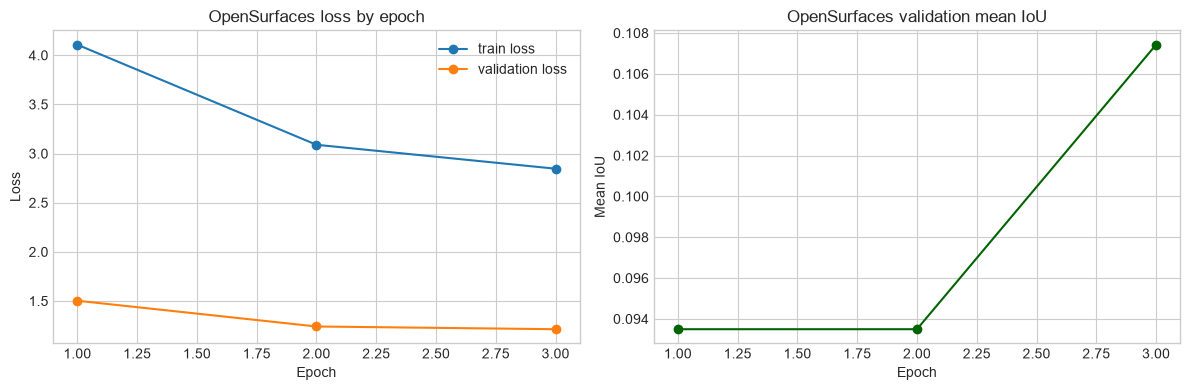

Best checkpoint: c:\Users\Samiha Abeda Nur\Downloads\Fitwell-AI\training\runs\opensurfaces-research\best.pt


In [6]:
print('The DMS model results are shown above.')
print('OpenSurfaces photos have been matched, invalid/ambiguous labels removed, and masks prepared.')
opensurfaces_run = ROOT / 'training' / 'runs' / 'opensurfaces-research'
opensurfaces_history = opensurfaces_run / 'history.csv'
if opensurfaces_history.exists():
    opensurfaces_results = pd.read_csv(opensurfaces_history)
    display(opensurfaces_results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(opensurfaces_results['epoch'], opensurfaces_results['train_loss'], marker='o', label='train loss')
    axes[0].plot(opensurfaces_results['epoch'], opensurfaces_results['validation_loss'], marker='o', label='validation loss')
    axes[0].set(title='OpenSurfaces loss by epoch', xlabel='Epoch', ylabel='Loss'); axes[0].legend()
    axes[1].plot(opensurfaces_results['epoch'], opensurfaces_results['validation_mean_iou'], marker='o', color='darkgreen')
    axes[1].set(title='OpenSurfaces validation mean IoU', xlabel='Epoch', ylabel='Mean IoU')
    plt.tight_layout(); plt.show()
    print('Best checkpoint:', opensurfaces_run / 'best.pt')
else:
    print('OpenSurfaces training has not been run yet.')


## Saved tables and graphs

The generated outputs are saved in `datasets/opensurfaces/analysis/` so they remain visible even before the notebook is run:

- `raw_photo_status_table.csv` and `raw_photo_status.png`
- `matched_annotation_table.csv`, `matched_material_labels_table.csv`, and `matched_material_labels.png`
- `cleaned_image_mask_table.csv`, `cleaned_split_table.csv`, and `cleaned_split.png`

Run **Run All** in VS Code to render the same tables and graphs directly inside this notebook.


## Research note

This workflow is for research use. Photo download and dataset use remain subject to the OpenSurfaces licence and attribution requirements.